# Step 3c — Error analysis (ResNet50, 20 models)

Course component 5: *show the failures, say what they have in common, propose explanations.*

We use all 20 grouped-split models from step 2 (4 imbalance methods × 5 folds). Because they all
predict the same test set, we can ask for every test image **how many of the 20 models got it wrong**.
That separates:
- **consistent failures** (wrong for (almost) every model): a property of the image or its label,
  not of one training run;
- **unstable images** (wrong for some models): borderline cases;
- **easy images** (right for every model).

Sections:
1. Setup
2. Load predictions of the 20 models
3. How consistent are the errors? → `error_consistency.png / .pdf`
4. What do the consistent failures look like? (image grids) → `failures_*.png`
5. What does class weighting fix? → `fixed_by_weights.png`
6. Confidence and calibration → `calibration.png / .pdf`
7. Does the center crop throw away the lesion? (re-scores 4 models on the full image; GPU or CPU)
8. Where does the model look? Grad-CAM on failures → `gradcam_failures.png`
9. Summary

**Image licence (course rule R12):** check the Cassava competition's data licence before putting
these image grids in the report or a public repository. This notebook embeds images in its outputs;
clear outputs before pushing to a public repo.

All outputs go to `reports/figures/error_analysis/`.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import confusion_matrix

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Deep_Learning").is_dir())
sys.path.insert(0, str(ROOT))
from Deep_Learning.config import IMAGE_DIR, RUNS_DIR, SPLITS_CSV, short_class_names

CLASSES = short_class_names()
K = len(CLASSES)
OUT = ROOT / "reports" / "figures" / "error_analysis"
OUT.mkdir(parents=True, exist_ok=True)

METHODS = ["none", "sampler", "weights", "oversample"]
LABEL = {"none": "None (baseline)", "sampler": "Weighted sampler",
         "weights": "Class-weighted loss", "oversample": "Oversampling"}
COLOR = {"none": "#2a78d6", "sampler": "#eb6834", "weights": "#1baf7a", "oversample": "#eda100"}
SURFACE, INK, INK_2, GRID = "#ffffff", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 72      # on-screen size only; saved files use their own dpi

def save(fig, stem, pdf=True):
    fig.savefig(OUT / f"{stem}.png", dpi=200, bbox_inches="tight")
    if pdf:
        fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")

def clean(ax, grid="y"):
    getattr(ax, f"{grid}axis").grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

## 2. Load predictions of the 20 models

`P` has shape (runs, images, classes). Every run is checked against its saved `test_metrics.json`.

In [2]:
test = pd.read_csv(SPLITS_CSV).query("split == 'test'").reset_index(drop=True)
y = test.label.to_numpy()

runs = []
for d in sorted(RUNS_DIR.glob("r50_*")):
    cfg = json.loads((d / "config.json").read_text())
    if cfg.get("split", "grouped") != "grouped" or cfg.get("train_frac", 1.0) != 1.0:
        continue
    probs = np.load(d / "test_probs.npy")
    saved = json.loads((d / "test_metrics.json").read_text())
    assert np.isclose((probs.argmax(1) == y).mean(), saved["test_acc"], atol=1e-6), d.name
    runs.append({"run": d.name, "method": cfg["imbalance"], "fold": cfg["val_fold"], "probs": probs})
runs = sorted(runs, key=lambda r: (METHODS.index(r["method"]), r["fold"]))
P = np.stack([r["probs"] for r in runs])                 # (20, n, 5)
pred = P.argmax(2)                                       # (20, n)
wrong = pred != y                                        # (20, n)
meth = np.array([r["method"] for r in runs])
print(P.shape, "-", len(runs), "runs:", sorted(set(meth)), "folds", sorted({r['fold'] for r in runs}))

(20, 3078, 5) - 20 runs: [np.str_('none'), np.str_('oversample'), np.str_('sampler'), np.str_('weights')] folds [0, 1, 2, 3, 4]


## 3. How consistent are the errors?

For each test image: the number of the 20 models that misclassify it.

In [3]:
n_wrong = wrong.sum(0)
test["n_wrong"] = n_wrong
# Most common prediction among the models that got it wrong
wrong_votes = np.stack([((pred == c) & wrong).sum(0) for c in range(K)], 1)
test["main_wrong_pred"] = np.where(n_wrong > 0, wrong_votes.argmax(1), -1)
test["mean_conf_true"] = P[:, np.arange(len(y)), y].mean(0)    # mean prob given to the true class

bins = {"always right (0/20)": n_wrong == 0, "sometimes wrong (1-17)": (n_wrong >= 1) & (n_wrong <= 17),
        "consistently wrong (18-20)": n_wrong >= 18}
table = pd.DataFrame({name: [int(m[y == c].sum()) for c in range(K)] + [int(m.sum())] for name, m in bins.items()},
                     index=CLASSES + ["All"])
table["% consistently wrong"] = (100 * table["consistently wrong (18-20)"] / table.sum(1)).round(1)
table

,always right (0/20),sometimes wrong (1-17),consistently wrong (18-20),% consistently wrong
CBB,43,77,29,19.5
CBSD,177,89,40,13.1
CGM,212,84,49,14.2
CMD,1672,166,42,2.2
Healthy,203,140,55,13.8
All,2307,556,215,7.0


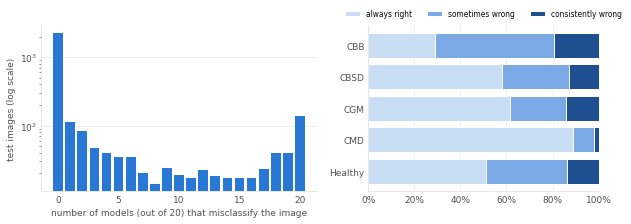

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
counts = np.bincount(n_wrong, minlength=21)
ax.bar(range(21), counts, color="#2a78d6", width=0.8)
ax.set_yscale("log")
ax.set_xlabel("number of models (out of 20) that misclassify the image")
ax.set_ylabel("test images (log scale)")
ax.set_xticks([0, 5, 10, 15, 20])
clean(ax)
ax = axes[1]
share = np.array([[((n_wrong[y == c] == 0).mean()), ((n_wrong[y == c] >= 1) & (n_wrong[y == c] <= 17)).mean(),
                   (n_wrong[y == c] >= 18).mean()] for c in range(K)])
left = np.zeros(K)
for j, (lab, col) in enumerate(zip(["always right", "sometimes wrong", "consistently wrong"],
                                   ["#c9ddf5", "#7aa9e6", "#1d4f91"])):
    ax.barh(range(K)[::-1], share[:, j], left=left, color=col, label=lab, edgecolor=SURFACE, lw=1)
    left += share[:, j]
ax.set_yticks(range(K)[::-1], CLASSES)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(ncol=3, frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, 1.0))
clean(ax, "x")
save(fig, "error_consistency")
plt.show()

In [5]:
# Consistent failures: true class vs the class most models predict instead
cf = test[test.n_wrong >= 18]
pd.crosstab(cf.label.map(dict(enumerate(CLASSES))), cf.main_wrong_pred.map(dict(enumerate(CLASSES))),
            rownames=["true"], colnames=["predicted by most models"], margins=True)

predicted by most models,CBB,CBSD,CGM,CMD,Healthy,All
true,,,,,,
CBB,0,8,3,1,17,29
CBSD,12,0,5,10,13,40
CGM,8,5,0,21,15,49
CMD,5,8,15,0,14,42
Healthy,17,11,14,13,0,55
All,42,32,37,45,59,215


## 4. What do the consistent failures look like?

Full 800×600 photos. The **dashed lines** mark the 384×384 center crop the model actually sees
(`Resize(384)` + `CenterCrop(384)` cuts off 64 px of the resized image on each side,
i.e. 25% of the width). Title: true → predicted (share of models), mean probability of the true class.

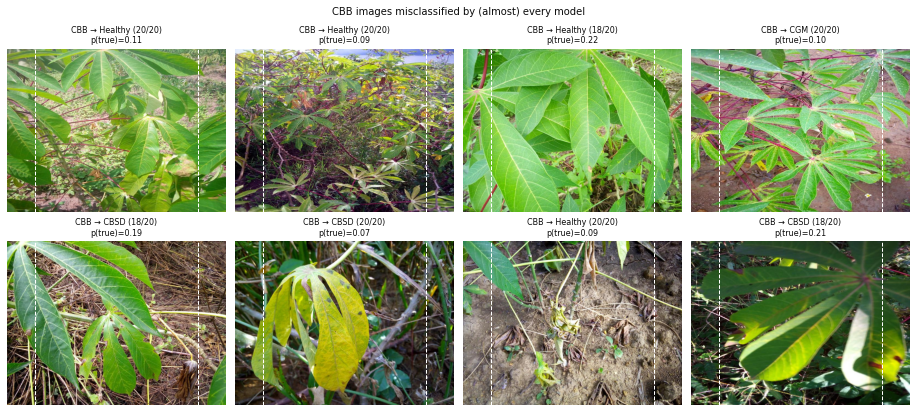

In [6]:
def show_grid(rows, title, stem, ncols=4, crop_lines=True, of=20):
    n = len(rows)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.0 * nrows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.ravel(axes), rows.iterrows()):
        with Image.open(IMAGE_DIR / r.image_id) as im:
            ax.imshow(im.convert("RGB"))
            w, h = im.size
        if crop_lines:   # visible region after Resize(short side 384) + CenterCrop(384)
            half = h / 2
            for x0 in (w / 2 - half, w / 2 + half):
                ax.axvline(x0, color="white", ls="--", lw=1)
        wp = CLASSES[r.main_wrong_pred] if r.main_wrong_pred >= 0 else "-"
        ax.set_title(f"{CLASSES[r.label]} → {wp} ({r.n_wrong}/{of})\np(true)={r.mean_conf_true:.2f}", fontsize=8)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    save(fig, stem, pdf=False)
    plt.show()

rng = np.random.default_rng(0)
def pick(df, n=8):
    return df.sample(min(n, len(df)), random_state=0) if len(df) else df

show_grid(pick(test[(test.label == CLASSES.index("CBB")) & (test.n_wrong >= 18)]),
          "CBB images misclassified by (almost) every model", "failures_cbb")

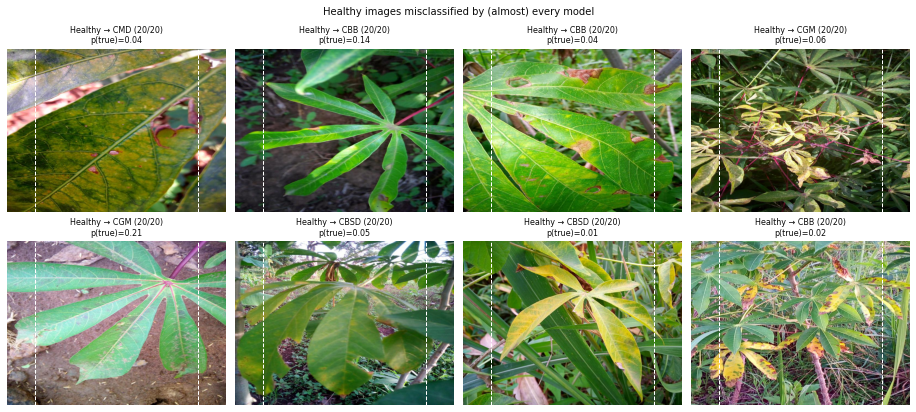

In [7]:
show_grid(pick(test[(test.label == CLASSES.index("Healthy")) & (test.n_wrong >= 18)]),
          "Healthy images misclassified by (almost) every model", "failures_healthy")

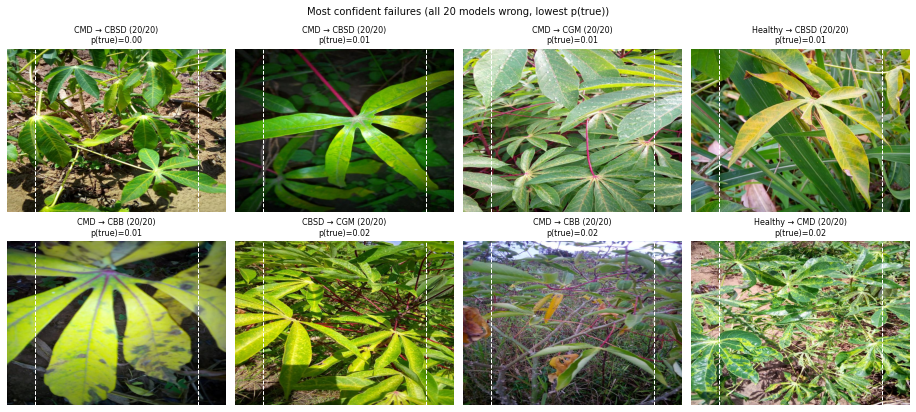

In [8]:
# Most confident failures: every model wrong AND almost no probability on the true class.
# These are the best candidates for label noise (Cassava's labels are known to be noisy) -- inspect them.
show_grid(test[test.n_wrong == 20].nsmallest(8, "mean_conf_true"),
          "Most confident failures (all 20 models wrong, lowest p(true))", "failures_most_confident")

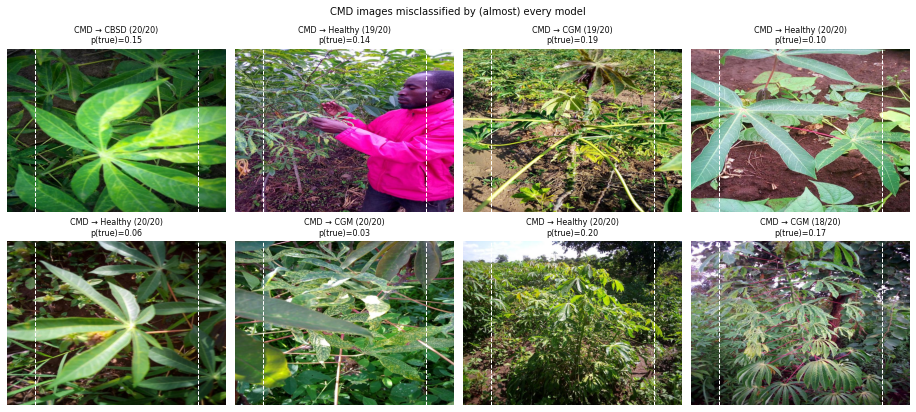

In [9]:
show_grid(pick(test[(test.label == CLASSES.index("CMD")) & (test.n_wrong >= 18)]),
          "CMD images misclassified by (almost) every model", "failures_cmd")

## 5. What does class weighting fix?

Images the baseline gets wrong in at least 4 of its 5 folds while class-weighted loss gets them right
in at least 4 of 5 (and the reverse: images that weighting breaks).

In [10]:
wb = wrong[meth == "none"].sum(0)       # 0-5
ww = wrong[meth == "weights"].sum(0)
fixed = test[(wb >= 4) & (ww <= 1)]
broken = test[(wb <= 1) & (ww >= 4)]
summary = pd.DataFrame({"fixed by weights": fixed.label.value_counts().reindex(range(K), fill_value=0).values,
                        "broken by weights": broken.label.value_counts().reindex(range(K), fill_value=0).values},
                       index=CLASSES)
summary.loc["All"] = summary.sum()
summary

,fixed by weights,broken by weights
CBB,3,0
CBSD,0,0
CGM,1,0
CMD,0,5
Healthy,3,0
All,7,5


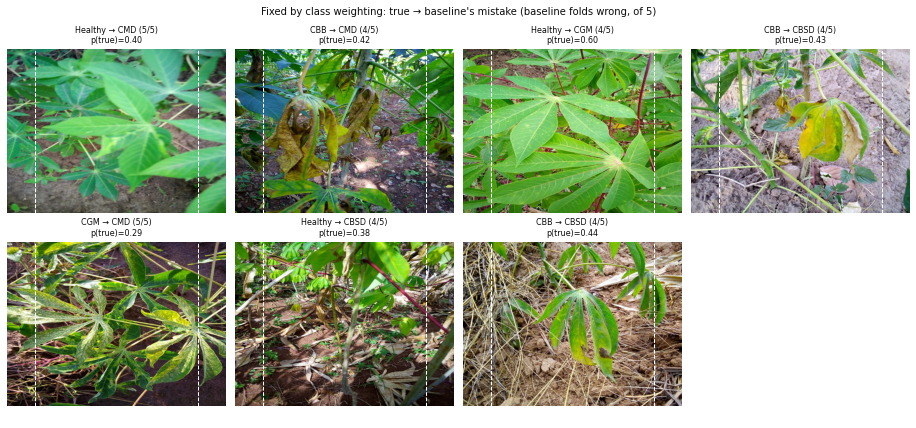

In [11]:
fx = fixed.copy()
fx["main_wrong_pred"] = [np.bincount(pred[meth == "none", i][pred[meth == "none", i] != y[i]], minlength=K).argmax()
                         for i in fx.index]
fx["n_wrong"] = wb[fx.index]
show_grid(pick(fx[fx.label != CLASSES.index("CMD")]),
          "Fixed by class weighting: true → baseline's mistake (baseline folds wrong, of 5)",
          "fixed_by_weights", of=5)

## 6. Confidence and calibration (course rule R6)

Is a model's confidence trustworthy? A **reliability diagram** bins predictions by confidence (max
probability) and plots the accuracy in each bin; a perfectly calibrated model lies on the diagonal.
**ECE** (expected calibration error) is the average gap, weighted by bin size. Computed per run,
then averaged over the 5 folds of each method.

In [12]:
def reliability(p, y, n_bins=10):
    conf, pr = p.max(1), p.argmax(1)
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(conf, edges) - 1, 0, n_bins - 1)
    acc = np.array([(pr[idx == b] == y[idx == b]).mean() if (idx == b).any() else np.nan for b in range(n_bins)])
    cbin = np.array([conf[idx == b].mean() if (idx == b).any() else np.nan for b in range(n_bins)])
    w = np.bincount(idx, minlength=n_bins) / len(y)
    ece = np.nansum(w * np.abs(acc - cbin))
    return cbin, acc, ece

rows = []
for r in runs:
    _, _, ece = reliability(r["probs"], y)
    conf = r["probs"].max(1)
    ok = r["probs"].argmax(1) == y
    rows.append({"method": r["method"], "fold": r["fold"], "ECE": ece,
                 "mean conf (correct)": conf[ok].mean(), "mean conf (wrong)": conf[~ok].mean()})
cal = pd.DataFrame(rows)
cal_summary = cal.groupby("method")[["ECE", "mean conf (correct)", "mean conf (wrong)"]].agg(["mean", "std"]).loc[METHODS]
cal_summary.to_csv(OUT / "calibration.csv", float_format="%.4f")
cal_summary

ECE        mean conf (correct)        mean conf (wrong)       
             mean    std                mean    std              mean    std
method                                                                      
none        0.044  0.010               0.864  0.014             0.650  0.023
sampler     0.038  0.015               0.863  0.015             0.662  0.018
weights     0.107  0.009               0.794  0.006             0.647  0.015
oversample  0.051  0.014               0.856  0.016             0.644  0.032

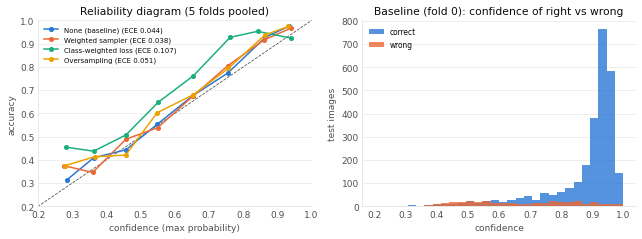

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
ax = axes[0]
ax.plot([0, 1], [0, 1], ls="--", color=INK_2, lw=0.8)
for m in METHODS:
    pm = np.concatenate([r["probs"] for r in runs if r["method"] == m])
    ym = np.concatenate([y for r in runs if r["method"] == m])
    cbin, acc, _ = reliability(pm, ym)
    ax.plot(cbin, acc, "o-", ms=4, lw=1.5, color=COLOR[m],
            label=f"{LABEL[m]} (ECE {cal_summary.loc[m, ('ECE', 'mean')]:.3f})")
ax.set(xlabel="confidence (max probability)", ylabel="accuracy", xlim=(0.2, 1), ylim=(0.2, 1),
       title="Reliability diagram (5 folds pooled)")
ax.legend(frameon=False, fontsize=7)
clean(ax)
ax = axes[1]
b = runs[0]["probs"]   # baseline fold 0
conf = b.max(1); ok = b.argmax(1) == y
ax.hist(conf[ok], bins=30, range=(0.2, 1), color="#2a78d6", alpha=0.8, label="correct")
ax.hist(conf[~ok], bins=30, range=(0.2, 1), color="#eb6834", alpha=0.8, label="wrong")
ax.set(xlabel="confidence", ylabel="test images", title="Baseline (fold 0): confidence of right vs wrong")
ax.legend(frameon=False, fontsize=7.5)
clean(ax)
fig.tight_layout()
save(fig, "calibration")
plt.show()

## 7. Does the center crop throw away the lesion?

Every photo is 800×600. Evaluation does `Resize(384)` (→ 512×384) and `CenterCrop(384)`, so the left
and right 12.5% of each photo are never seen at test time. If symptoms near the edges matter, scoring
the **whole** 512×384 image should help. ResNet ends in global average pooling, so it accepts the
non-square input without changes. We re-score the 4 fold-0 models (GPU if free, otherwise CPU, a few minutes).

This changes only the test-time input, not training, and is reported as an analysis, not used to pick a model.

In [14]:
import torch
from torchvision import transforms as T
from Deep_Learning.config import IMAGENET_MEAN, IMAGENET_STD
from Deep_Learning.models import build_resnet

import os, subprocess

def pick_device(min_free_mib=6000):
    # Pick the GPU with most free memory via nvidia-smi (does not touch the other GPUs), else CPU.
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=index,memory.free,memory.total",
                              "--format=csv,noheader,nounits"], capture_output=True, text=True, check=True).stdout
        gpus = [tuple(int(v) for v in line.split(",")) for line in out.strip().splitlines()]
        gpus = [g for g in gpus if g[2] >= 16000 and g[1] >= min_free_mib]   # skip small display cards
    except Exception:
        gpus = []
    if not gpus or "CUDA_VISIBLE_DEVICES" in os.environ and os.environ["CUDA_VISIBLE_DEVICES"] == "":
        return torch.device("cpu")
    best = max(gpus, key=lambda g: g[1])[0]
    os.environ.setdefault("CUDA_DEVICE_ORDER", "PCI_BUS_ID")
    return torch.device(f"cuda:{best}")

device = pick_device()
print("device:", device)

def load_model(run_name):
    ckpt = torch.load(RUNS_DIR / run_name / "best.pt", map_location="cpu")
    m = build_resnet(ckpt["args"]["model"], K, pretrained=False, dropout=ckpt["args"]["dropout"])
    m.load_state_dict(ckpt["model"])
    return m.to(device).eval()

full_tf = T.Compose([T.Resize(384), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])  # 512x384, no crop

@torch.no_grad()
def predict_full(model, batch=64):
    out = []
    for i in range(0, len(test), batch):
        xb = torch.stack([full_tf(Image.open(IMAGE_DIR / f).convert("RGB")) for f in test.image_id[i:i + batch]])
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            out.append(torch.softmax(model(xb.to(device)).float(), 1).cpu().numpy())
    return np.concatenate(out)

device: cuda:0


In [15]:
from sklearn.metrics import balanced_accuracy_score, f1_score

fold0 = {r["method"]: r for r in runs if r["fold"] == 0}
rows, full_probs = [], {}
for m in METHODS:
    model = load_model(fold0[m]["run"])
    pf = full_probs[m] = predict_full(model)
    pc = fold0[m]["probs"]
    for name, p in [("center crop 384x384 (as trained)", pc), ("full image 512x384", pf)]:
        rows.append({"method": m, "input": name, "macro_f1": f1_score(y, p.argmax(1), average="macro"),
                     "balanced_acc": balanced_accuracy_score(y, p.argmax(1)),
                     "recall CBB": (p.argmax(1)[y == 0] == 0).mean()})
    del model
crop_cmp = pd.DataFrame(rows).pivot(index="method", columns="input").loc[METHODS]
crop_cmp.to_csv(OUT / "center_crop_vs_full.csv", float_format="%.4f")
(100 * crop_cmp).round(1)

macro_f1                     \
input      center crop 384x384 (as trained) full image 512x384   
method                                                           
none                                   77.5               78.1   
sampler                                76.4               76.0   
weights                                78.5               78.4   
oversample                             78.0               78.4   

                               balanced_acc                     \
input      center crop 384x384 (as trained) full image 512x384   
method                                                           
none                                   77.5               77.8   
sampler                                77.6               77.0   
weights                                79.8               79.3   
oversample                             78.7               78.7   

                                 recall CBB                     
input      center crop 384x384 (as trained) full image 512x384  
method                                                          
none                                   63.8               63.1  
sampler                                65.8               63.1  
weights                                70.5               66.4  
oversample                             66.4               63.8

## 8. Where does the model look? Grad-CAM on failures

Grad-CAM highlights the image regions that pushed the model towards its prediction (last conv block,
`layer4`). Shown for the baseline fold-0 model on consistent CBB failures. If the heat sits on
background, soil or a healthy leaf instead of the lesion, the model is using the wrong evidence.

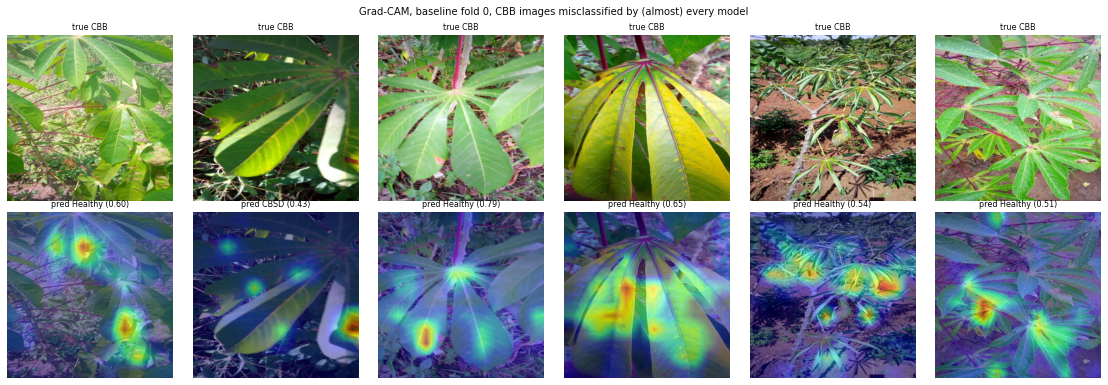

In [16]:
crop_tf = T.Compose([T.Resize(384), T.CenterCrop(384), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

def gradcam(model, x, target):
    feats, grads = {}, {}
    def fwd(m, i, o):   # keep the activation and a hook on its gradient
        feats["a"] = o
        o.register_hook(lambda g: grads.__setitem__("g", g))
    h = model.layer4.register_forward_hook(fwd)
    model.zero_grad()
    logits = model(x)
    logits[0, target].backward()
    h.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = torch.relu((w * feats["a"]).sum(1))[0]
    cam = torch.nn.functional.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear")[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy(), logits.softmax(1)[0].detach().cpu().numpy()

model = load_model(fold0["none"]["run"])
base_wrong = fold0["none"]["probs"].argmax(1) != y      # this model must also be wrong on the image
sel = pick(test[(test.label == CLASSES.index("CBB")) & (test.n_wrong >= 18) & base_wrong], 6)
fig, axes = plt.subplots(2, len(sel), figsize=(2.6 * len(sel), 5.4))
for j, (_, r) in enumerate(sel.iterrows()):
    img = Image.open(IMAGE_DIR / r.image_id).convert("RGB")
    x = crop_tf(img)[None].to(device).requires_grad_(True)
    p_pred = int(fold0["none"]["probs"][r.name].argmax())
    cam, prob = gradcam(model, x, p_pred)
    shown = np.asarray(T.CenterCrop(384)(T.Resize(384)(img)))
    axes[0, j].imshow(shown); axes[0, j].set_title(f"true {CLASSES[r.label]}", fontsize=8)
    axes[1, j].imshow(shown); axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, j].set_title(f"pred {CLASSES[p_pred]} ({prob[p_pred]:.2f})", fontsize=8)
    axes[0, j].axis("off"); axes[1, j].axis("off")
fig.suptitle("Grad-CAM, baseline fold 0, CBB images misclassified by (almost) every model", fontsize=10)
fig.tight_layout()
save(fig, "gradcam_failures", pdf=False)
plt.show()
del model

## 9. Summary

Numbers for the report, printed from the cells above. The *interpretation* (what the failures have
in common) should come from looking at the image grids yourself: confirm or correct the patterns
before writing them up.

In [17]:
print("Error consistency over 20 models:")
for name, m in bins.items():
    print(f"  {name:<28} {m.sum():5d} images ({m.mean():.1%})")
print("\nConsistent failures by class (18-20 of 20 models wrong):")
for c in CLASSES:
    print(f"  {c:<8} {int(table.loc[c, 'consistently wrong (18-20)']):4d} of {int(table.loc[c].iloc[:3].sum()):4d} "
          f"({table.loc[c, '% consistently wrong']}%)")
top = pd.crosstab(cf.label, cf.main_wrong_pred).stack().sort_values(ascending=False).head(4)
print("\nMost common consistent confusions (true -> predicted):")
for (t, p), n in top.items():
    print(f"  {CLASSES[t]:<8} -> {CLASSES[p]:<8} {n}")
print(f"\nClass weighting fixes {len(fixed)} images and breaks {len(broken)} (>=4/5 folds rule)")
print("\nCalibration (ECE, mean over folds):",
      ", ".join(f"{m} {cal_summary.loc[m, ('ECE', 'mean')]:.3f}" for m in METHODS))
print("\nCenter crop vs full image (fold 0, macro-F1 %):")
for m in METHODS:
    a = 100 * crop_cmp.loc[m, ("macro_f1", "center crop 384x384 (as trained)")]
    b = 100 * crop_cmp.loc[m, ("macro_f1", "full image 512x384")]
    print(f"  {LABEL[m]:<20} crop {a:.1f} -> full {b:.1f} ({b - a:+.1f})")
print("\nFiles in", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

Error consistency over 20 models:
  always right (0/20)           2307 images (75.0%)
  sometimes wrong (1-17)         556 images (18.1%)
  consistently wrong (18-20)     215 images (7.0%)

Consistent failures by class (18-20 of 20 models wrong):
  CBB        29 of  149 (19.5%)
  CBSD       40 of  306 (13.1%)
  CGM        49 of  345 (14.2%)
  CMD        42 of 1880 (2.2%)
  Healthy    55 of  398 (13.8%)

Most common consistent confusions (true -> predicted):
  CGM      -> CMD      21
  Healthy  -> CBB      17
  CBB      -> Healthy  17
  CGM      -> Healthy  15

Class weighting fixes 7 images and breaks 5 (>=4/5 folds rule)

Calibration (ECE, mean over folds): none 0.044, sampler 0.038, weights 0.107, oversample 0.051

Center crop vs full image (fold 0, macro-F1 %):
  None (baseline)      crop 77.5 -> full 78.1 (+0.5)
  Weighted sampler     crop 76.4 -> full 76.0 (-0.4)
  Class-weighted loss  crop 78.5 -> full 78.4 (-0.2)
  Oversampling         crop 78.0 -> full 78.4 (+0.3)

Files in /ho